# MEMC exercise 7 – Variance reduction

---

The Monte Carlo error falls off like $\sigma/\sqrt N$. If we want a result ten times as accurate, we
need **a hundred times** as many samples. There is a second route: make **$\sigma$** smaller. The
same expectation can in fact be estimated by many different random variables, and they differ in
variance.

In this notebook we compare four tricks on a single example, $I = \int_0^1 e^{-x^2}\,dx$ (known from
exercise 1):

| Trick | The idea |
|-------|----------|
| the sample mean instead of hit-or-miss | use the value of the function, not just the "below / above" bit |
| a control variate | subtract something similar whose expectation we know |
| stratification | spread the points more evenly than pure chance does |
| importance sampling | generate where the integrand matters |

At the end you see that for **rare events** (exercise 2) the last trick is the difference between
"the estimate is zero" and an accurate result.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(xs):
    '''The average and the standard error from a finished list of values.'''
    n = len(xs)
    mean = sum(xs) / n
    var = sum((x - mean) ** 2 for x in xs) / (n - 1)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {mean:.6g} +- {se:.3g}  (exact {exact:.6g})")
    assert abs(mean - exact) <= k * se, name


def Phi(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


f = lambda x: math.exp(-x * x)
Z = math.sqrt(math.pi) / 2 * math.erf(1)  # the exact value of the integral
print(f"I = {Z:.6f}")

I = 0.746824


## 1. What we want to measure

We estimate with $N$ independent repetitions, and the quality of the estimate is described by the
**variance of a single contribution** $\sigma^2$: the standard error is $\sigma/\sqrt N$. So at the
same $N$, the better method is the one with the smaller $\sigma^2$.

The methods also differ in the **cost** of a single contribution (some need two random numbers,
others an extra evaluation). A fair comparison therefore tracks the variance at **the same number of
function evaluations**, which is what we will do.

We measure the variance **by experiment**: we repeat each method with $N$ points $R$ times and compute
the standard deviation of the $R$ estimates. That is the actual error of the estimate directly — no
theory, no assumptions.

## 2. The sample mean instead of hit-or-miss

In exercise 1 we estimated the integral in two ways:

- **hit-or-miss:** a point $(\gamma_1, \gamma_2)$ in the unit square,
  $\mathbb 1[\gamma_2 < f(\gamma_1)]$; the variance of one contribution is $I(1-I)$.
- **the sample mean:** $f(\gamma)$ with $\gamma \sim R(0,1)$; the variance of one contribution is
  $D f(\gamma) = \int_0^1 f^2 - I^2$.

The second approach uses the **whole value** $f(\gamma)$, the first only a single bit of information
("is the point below the graph?"). From the Rao–Blackwell principle it follows that the sample mean
cannot have the larger variance, because it is the expectation of hit-or-miss over $\gamma_2$ at a
fixed $\gamma_1$.

In [2]:
def hit_or_miss(N):
    return sum(random.random() < f(random.random()) for _ in range(N)) / N


def sample_mean(N):
    return sum(f(random.random()) for _ in range(N)) / N


# the exact variances of a single contribution
var_hm = Z * (1 - Z)
int_f2 = math.sqrt(math.pi / 8) * math.erf(math.sqrt(2))  # the integral of e^{-2x^2} over [0,1]
var_mean = int_f2 - Z ** 2
print(f"hit-or-miss: Var = {var_hm:.4f}")
print(f"sample mean: Var = {var_mean:.4f}   (ratio {var_hm / var_mean:.1f}x)")

hit-or-miss: Var = 0.1891
sample mean: Var = 0.0404   (ratio 4.7x)


The sample mean has about $4.7\times$ the smaller variance, which is the same thing as $4.7\times$
fewer samples for the same accuracy. And it is **free**: the same code, just a different estimator.

## 3. Antithetic variables

If $f$ is monotone (here decreasing), the values $f(\gamma)$ and $f(1-\gamma)$ are **negatively
correlated**: a large $\gamma$ gives a small $f$ and vice versa. Their average then has a smaller
variance than the average of two independent ones:

$$D\frac{f(\gamma)+f(1-\gamma)}{2} = \frac{D f(\gamma)}{2}\,\bigl(1 + \operatorname{Corr}(f(\gamma), f(1-\gamma))\bigr).$$

At the same number of evaluations we use $N/2$ pairs $(\gamma, 1-\gamma)$.

In [3]:
def antithetic(N):
    s = 0.0
    for _ in range(N // 2):
        u = random.random()
        s += f(u) + f(1 - u)
    return s / N

## 4. A control variate

The function $f(x) = e^{-x^2}$ can be replaced by a nearby function whose integral we know exactly:
$h(x) = 1 - x^2$, say (the first two terms of the Taylor expansion), with $\int_0^1 h = \tfrac23$.
Then

$$I = \underbrace{\int_0^1 \bigl(f - c\,h\bigr)}_{\text{estimated by MC}} + c\cdot\tfrac23,$$

i.e. the estimator $f(\gamma) - c\,\bigl(h(\gamma) - \tfrac23\bigr)$. Its expectation is still $I$ (we
are subtracting a term with zero expectation), but if $h$ is close to $f$, the difference is almost
constant and **the variance is small**.

The optimal choice is $c^\star = \dfrac{\operatorname{Cov}(f(\gamma), h(\gamma))}{D\, h(\gamma)}$. The
simplest is $c = 1$ (just subtract $h$), but the optimum tends to be elsewhere: in the test we see
both variants.

In [4]:
h = lambda x: 1 - x * x
Eh = 2 / 3


def control_variate(N, c):
    s = 0.0
    for _ in range(N):
        u = random.random()
        s += f(u) - c * (h(u) - Eh)
    return s / N


# we estimate the optimal c from a pilot sample (kept separate from the real simulation, so it introduces no bias)
pilot = [random.random() for _ in range(50_000)]
fv = [f(u) for u in pilot]
hv = [h(u) for u in pilot]
mf, mh = sum(fv) / len(fv), sum(hv) / len(hv)
cov = sum((a - mf) * (b - mh) for a, b in zip(fv, hv)) / (len(fv) - 1)
var_h = sum((b - mh) ** 2 for b in hv) / (len(hv) - 1)
c_opt = cov / var_h
print(f"optimal c ≈ {c_opt:.3f}")
corr = cov / math.sqrt(var_h * sum((a - mf) ** 2 for a in fv) / (len(fv) - 1))
print(f"correlation of f(γ) and h(γ) ≈ {corr:.4f}")
print(f"expected variance reduction at c*: 1 / (1 - corr^2) ≈ {1 / (1 - corr ** 2):.0f}x versus the sample mean")

optimal c ≈ 0.668
correlation of f(γ) and h(γ) ≈ 0.9924
expected variance reduction at c*: 1 / (1 - corr^2) ≈ 66x versus the sample mean


Why a control variate works can be seen from the picture: on the left $f$ and $h$ have a similar
shape, so their difference is smooth and fluctuates far less than $f$ itself (the point is not that
it is small, but that its variance is small); on the right the pairs $(h(\gamma), f(\gamma))$ lie
almost on a straight line. The slope of that line is exactly $c^\star$.

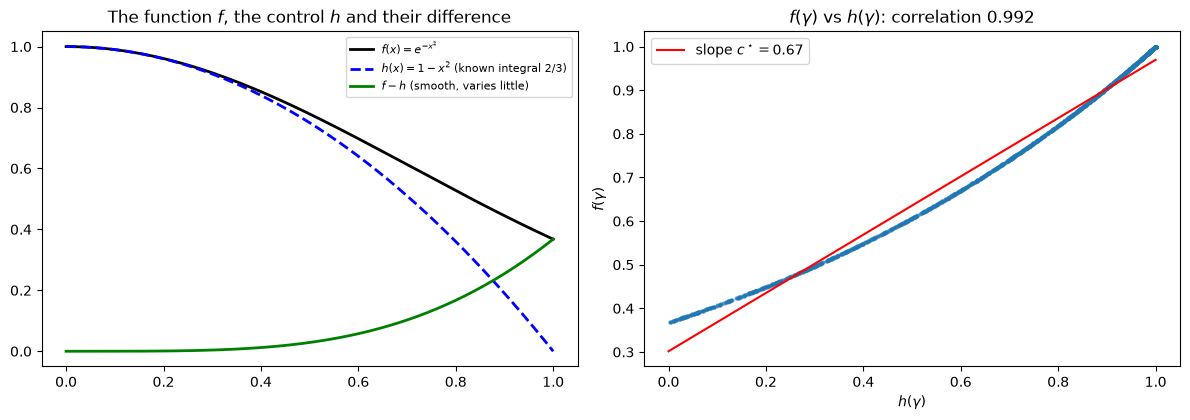

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
gr = [i / 200 for i in range(201)]
ax = axes[0]
ax.plot(gr, [f(x) for x in gr], "k", lw=2, label="$f(x) = e^{-x^2}$")
ax.plot(gr, [h(x) for x in gr], "b--", lw=2, label="$h(x) = 1 - x^2$ (known integral $2/3$)")
ax.plot(gr, [f(x) - h(x) for x in gr], "g", lw=2, label="$f - h$ (smooth, varies little)")
ax.set_title("The function $f$, the control $h$ and their difference")
ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(hv[:1500], fv[:1500], s=4, alpha=0.5)
hh = [min(hv), max(hv)]
ax.plot(hh, [mf + c_opt * (t - mh) for t in hh], "r", label=f"slope $c^\\star = {c_opt:.2f}$")
ax.set_xlabel("$h(\\gamma)$")
ax.set_ylabel("$f(\\gamma)$")
ax.set_title(f"$f(\\gamma)$ vs $h(\\gamma)$: correlation {corr:.3f}")
ax.legend()
plt.tight_layout()
plt.show()

The correlation is almost $1$, but $c^\star \approx 0.67$, not $1$: $h$ varies more than $f$ (from $1$
down to $0$, whereas $f$ only from $1$ down to $0.37$), so it has to be "toned down". At the optimal
$c^\star$ the variance shrinks by a factor of $1 - \operatorname{Corr}^2$, i.e. roughly sixtyfold (for
this problem). Choosing $c$ badly costs a lot: $c = 1$ gives only about a fourfold improvement.

## 5. Stratification

Pure chance behaves lumpily: one stretch of $[0,1]$ gets more points, another fewer (and the "gaps"
are exactly what raises the variance). **Stratification**: we cut $[0,1]$ into $N$ equal segments
(strata) and put **one** random point into each:

$$x_i = \frac{i + \gamma_i}{N},\quad i = 0,\dots,N-1.$$

Each point is still uniform on its own segment and the estimate is still unbiased, but the points are
spread more evenly. The variance of the estimate then falls considerably faster than $1/N$.

In [6]:
def stratified(N):
    return sum(f((i + random.random()) / N) for i in range(N)) / N

How the **spread of the points** differs: three ways of picking $N = 20$ points from $[0, 1]$. The
random points cluster and leave gaps. The antithetic pairs are symmetric about $1/2$ (joined by a
line). The stratified points sit one in each of the $20$ equal segments.

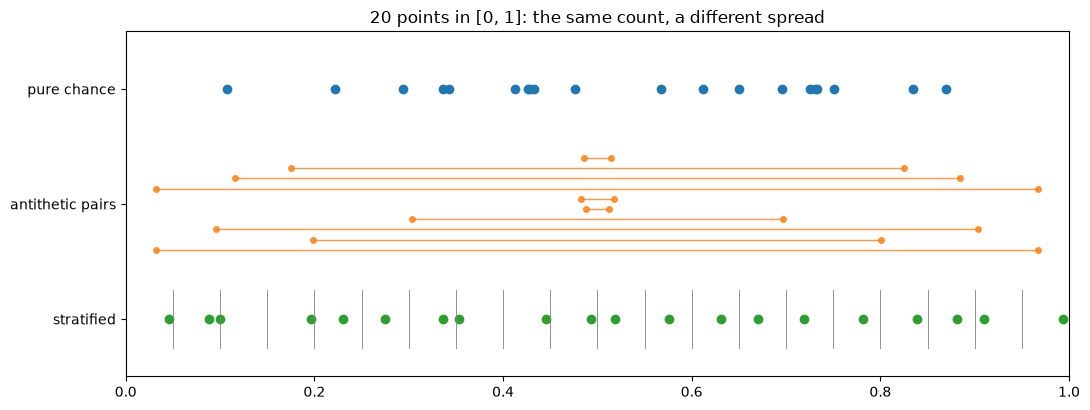

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.2))
Nn = 20
ax.scatter([random.random() for _ in range(Nn)], [2] * Nn, color="tab:blue")
for i in range(Nn // 2):
    u = random.random()
    yy = 0.6 + 0.8 * i / (Nn // 2 - 1)   # the pairs slightly above one another, so they stay visible
    ax.plot([u, 1 - u], [yy, yy], "o-", color="tab:orange", alpha=0.8, ms=4, lw=1)
ax.scatter([(i + random.random()) / Nn for i in range(Nn)], [0] * Nn, color="tab:green")
for i in range(Nn + 1):
    ax.plot([i / Nn] * 2, [-0.25, 0.25], color="gray", lw=0.6)
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["stratified", "antithetic pairs", "pure chance"])
ax.set_ylim(-0.5, 2.5)
ax.set_xlim(0, 1)
ax.set_title(f"{Nn} points in [0, 1]: the same count, a different spread")
plt.tight_layout()
plt.show()

## 6. A comparison by experiment

We repeat each method $R = 200$ times for several values of $N$ and compute the standard deviation of
the estimates. Every method gets **the same number of evaluations of $f$** ($N$); hit-or-miss
additionally consumes two random numbers per point.

In [8]:
methods = {
    "hit-or-miss": hit_or_miss,
    "sample mean": sample_mean,
    "antithetic": antithetic,
    "control, c = 1": lambda N: control_variate(N, 1.0),
    "control, c = c*": lambda N: control_variate(N, c_opt),
    "stratified": stratified,
}

R = 200
Ns = [100, 300, 1000, 3000, 10_000]
se_emp = {name: [] for name in methods}

for N in Ns:
    for name, method in methods.items():
        estimates = [method(N) for _ in range(R)]
        m, se_m = estimate(estimates)
        # unbiasedness: the average of the R estimates has to match the exact value (se_m is the error of that average)
        assert abs(m - Z) < 5 * se_m + 1e-12, (name, N, m)
        se_emp[name].append(math.sqrt(sum((x - m) ** 2 for x in estimates) / (R - 1)))

print(f"{'method':20s}" + "".join(f"{'N=' + str(N):>12s}" for N in Ns))
for name, ses in se_emp.items():
    print(f"{name:20s}" + "".join(f"{s:12.2e}" for s in ses))

method                     N=100       N=300      N=1000      N=3000     N=10000
hit-or-miss             4.52e-02    2.54e-02    1.36e-02    7.96e-03    4.90e-03
sample mean             2.14e-02    1.08e-02    6.43e-03    3.64e-03    2.02e-03
antithetic              4.27e-03    2.17e-03    1.39e-03    6.85e-04    4.28e-04
control, c = 1          1.09e-02    5.94e-03    3.08e-03    1.77e-03    8.67e-04
control, c = c*         2.45e-03    1.44e-03    8.10e-04    4.66e-04    2.24e-04
stratified              2.04e-04    3.77e-05    6.09e-06    1.16e-06    1.79e-07


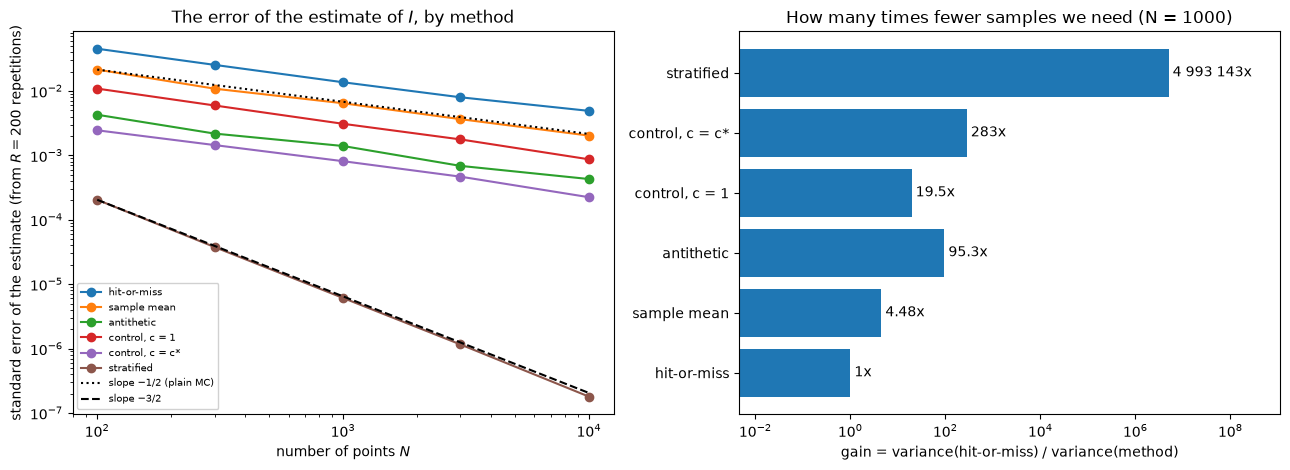

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
for name, ses in se_emp.items():
    ax.loglog(Ns, ses, "o-", label=name)
ref = se_emp["sample mean"][0]
ax.loglog(Ns, [ref * (Ns[0] / N) ** 0.5 for N in Ns], "k:", label="slope $-1/2$ (plain MC)")
ax.loglog(Ns, [se_emp["stratified"][0] * (Ns[0] / N) ** 1.5 for N in Ns], "k--", label="slope $-3/2$")
ax.set_xlabel("number of points $N$")
ax.set_ylabel("standard error of the estimate (from $R = 200$ repetitions)")
ax.set_title("The error of the estimate of $I$, by method")
ax.legend(fontsize=7, loc="lower left", framealpha=0.9)

# right: how many times fewer samples a method needs compared with hit-or-miss at N = 1000
i = Ns.index(1000)
base = se_emp["hit-or-miss"][i] ** 2
order = list(methods)
gain = [base / se_emp[n][i] ** 2 for n in order]
axes[1].barh(order, gain, color="tab:blue")
axes[1].set_xscale("log")
axes[1].set_xlabel("gain = variance(hit-or-miss) / variance(method)")
axes[1].set_title("How many times fewer samples we need (N = 1000)")
axes[1].margins(x=0.35)
for k, v in enumerate(gain):
    label_ = f" {v:,.0f}x".replace(",", " ") if v >= 100 else f" {v:.3g}x"
    axes[1].text(v, k, label_, va="center")
plt.tight_layout()
plt.show()

What follows from the picture:

- **Plain MC** (hit-or-miss, the sample mean) falls off with slope $-\tfrac12$, and the difference
  between them is a constant factor.
- **Antithetic variables and the control variate** shift the whole curve downwards, but the slope
  stays $-\tfrac12$: what changed is the constant $\sigma$. The difference between $c = 1$ and
  $c = c^\star$ is clearly visible.
- **Stratification** changes the **slope** as well: the error falls roughly like $N^{-3/2}$ (the
  variance like $N^{-3}$), so its advantage grows with $N$.

Stratification is this strong for smooth one-dimensional functions. In more dimensions you need
strata in every coordinate (and there are exponentially many of those), so the advantage shrinks.
Control variates and importance sampling are not troubled by the dimension.

## 7. Importance sampling

So far we generated from $R(0,1)$ and changed the estimator. Now we change **the distribution we
generate from**. We want

$$I = \int f(x)\,dx = \int \frac{f(x)}{g(x)}\,g(x)\,dx = E_g\!\left[\frac{f(X)}{g(X)}\right],\qquad X \sim g.$$

The estimator is $\dfrac{f(X)}{g(X)}$ with $X \sim g$ (**the weight** $w = f/g$). It works for **any**
density $g$ that is positive everywhere $f \neq 0$. The variance is small when $g$ is **similar to
$|f|$**: then $f/g$ is almost constant. The best (but unavailable) $g$ is proportional to $|f|$, where
$f/g$ would be exactly constant.

### 7.1 A rare event: $P(X > 4)$ for $X \sim N(0,1)$

Exactly, $P(X>4) = 1 - \Phi(4) \approx 3.17\cdot 10^{-5}$. Plain MC expects only about $32$ hits in a
million trials; in $100\,000$ trials about $3$, which is exactly the situation from exercise 2 where
the interval estimate broke down.

A good proposal: generate **where the event happens**. We take $g(x) = \varphi(x - 4)$ (the normal
distribution shifted to the point $4$). The weight is

$$w(x) = \frac{\varphi(x)}{\varphi(x-4)} = e^{-4x + 8}.$$

In [10]:
threshold = 4.0
exact_tail = 0.5 * math.erfc(threshold / math.sqrt(2))  # 1 - Phi(4), stable even for small numbers
print(f"exactly P(X > {threshold:.0f}) = {exact_tail:.4e}")

N = 100_000

# plain MC
hits = [1.0 if random.gauss(0, 1) > threshold else 0.0 for _ in range(N)]
m_plain, se_plain = estimate(hits)
print(f"plain MC:            {m_plain:.3e} +- {se_plain:.1e}   (hits: {int(sum(hits))})")

# importance sampling: x ~ N(4, 1), contribution = 1[x > 4] * exp(-4 x + 8)
def is_contribution():
    x = random.gauss(threshold, 1)
    return math.exp(-threshold * x + threshold * threshold / 2) if x > threshold else 0.0


weighted = [is_contribution() for _ in range(N)]
m_is, se_is = estimate(weighted)
check("importance sampling", m_is, se_is, exact_tail)
print(f"variance improvement: {(se_plain / se_is) ** 2:.0f}x")

exactly P(X > 4) = 3.1671e-05
plain MC:            2.000e-05 +- 1.4e-05   (hits: 2)
importance sampling: 3.15967e-05 +- 2.13e-07  (exact 3.16712e-05)
variance improvement: 4400x


At the same $N$ the estimate is **thousands of times** more accurate. Plain MC sees only a handful of
hits and the estimate is very unreliable; with the weighting, half of the points (those with
$x > 4$) are useful.

Let us look at the picture: where the density $\varphi$ lies, where the proposal $g$ lies, and how the
estimates behave as $N$ grows.

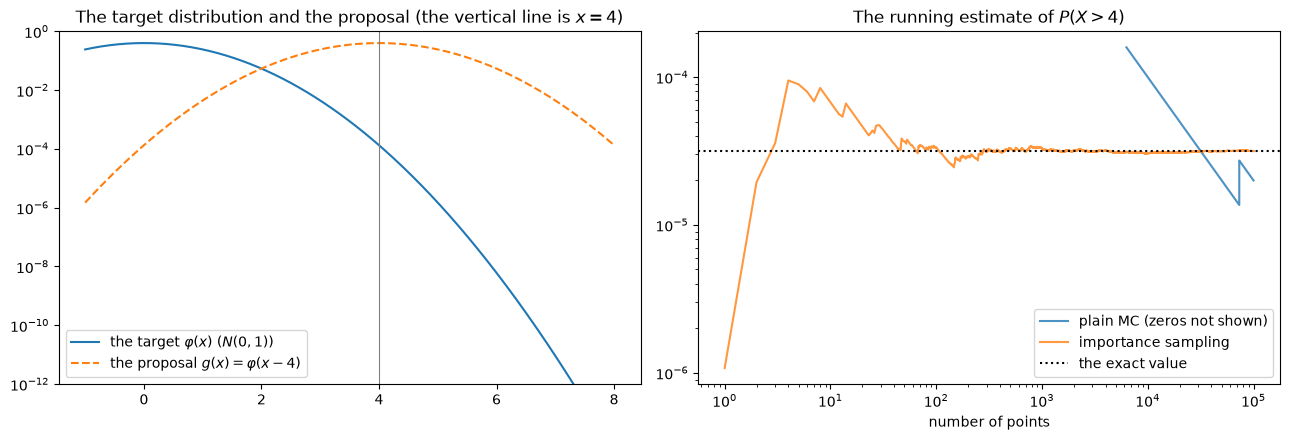

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

xs_ = [i / 50 - 1 for i in range(0, 451)]
phi = lambda x: math.exp(-x * x / 2) / math.sqrt(2 * math.pi)
axes[0].semilogy(xs_, [phi(x) for x in xs_], label=r"the target $\varphi(x)$ ($N(0,1)$)")
axes[0].semilogy(xs_, [phi(x - threshold) for x in xs_], "--", label=r"the proposal $g(x) = \varphi(x-4)$")
axes[0].axvline(threshold, color="gray", lw=0.8)
axes[0].set_ylim(1e-12, 1)
axes[0].set_title(r"The target distribution and the proposal (the vertical line is $x = 4$)")
axes[0].legend()

# the running estimate
def running(values):
    s, out = 0.0, []
    for i, v in enumerate(values, 1):
        s += v
        out.append(s / i)
    return out

ax = axes[1]
idx = list(range(1, N + 1))
ax.loglog(idx, [v if v > 0 else None for v in running(hits)], alpha=0.8, label="plain MC (zeros not shown)")
ax.loglog(idx, running(weighted), alpha=0.8, label="importance sampling")
ax.axhline(exact_tail, color="k", ls=":", label="the exact value")
ax.set_xlabel("number of points")
ax.set_title("The running estimate of $P(X > 4)$")
ax.legend()
plt.tight_layout()
plt.show()

On the left you can see that the proposal $g$ sits exactly where the event is. On the right, plain MC
gives zero for a long time and then jumps in multiples of $1/N$, while the weighted estimate settles
quickly at the exact value.

### 7.2 A singularity: $\int_0^1 \dfrac{\cos x}{\sqrt x}\,dx$

The integrand goes to infinity as $x \to 0$. Plain MC with $R(0,1)$ works (the integral converges),
but $D\bigl(f(\gamma)\bigr) = \int \dfrac{\cos^2 x}{x}\,dx = \infty$. For such an estimate the CLT in
its usual form does not hold, the error is large, and the standard error computed from the sample is
unreliable.

We take $g(x) = \dfrac{1}{2\sqrt x}$ on $(0,1]$. The density has **the same singularity** as the
integrand, so the weight $w = f/g = 2\cos x$ cancels it. We can sample from it by the inverse
transform: $G(x) = \sqrt x$, hence $X = \gamma^2$.

In [12]:
# the exact value: the substitution x = t^2 gives 2 * integral of cos(t^2) dt over [0,1], by Simpson's rule
def simpson(fun, a, b, n=2000):
    hh = (b - a) / n
    s = fun(a) + fun(b)
    for i in range(1, n):
        s += (4 if i % 2 else 2) * fun(a + i * hh)
    return s * hh / 3


I_sing = 2 * simpson(lambda t: math.cos(t * t), 0.0, 1.0)
print(f"exactly I = {I_sing:.8f}")


def plain_sing():
    u = 1.0 - random.random()  # (0, 1], avoids a division by zero
    return math.cos(u) / math.sqrt(u)


def is_sing():
    x = (1.0 - random.random()) ** 2  # X ~ g(x) = 1 / (2 sqrt(x))
    return 2 * math.cos(x)


R = 200
print(f"{'N':>8s} {'plain MC':>16s} {'weighted':>14s}")
for N in (1000, 10_000):
    se_p = estimate([sum(plain_sing() for _ in range(N)) / N for _ in range(R)])[1] * math.sqrt(R)
    se_i = estimate([sum(is_sing() for _ in range(N)) / N for _ in range(R)])[1] * math.sqrt(R)
    print(f"{N:8d} {se_p:16.2e} {se_i:14.2e}")

check("weighted, N = 100000", *estimate([is_sing() for _ in range(100_000)]), I_sing)

exactly I = 1.80904848
       N         plain MC       weighted
    1000         9.71e-02       8.06e-03


   10000         3.69e-02       2.47e-03
weighted, N = 100000: 1.81026 +- 0.000788  (exact 1.80905)


(The table shows the actual standard error of the estimate from $R = 200$ repetitions.) The weighting
gives a markedly smaller error, and reliably so: the weight $2\cos x$ is bounded, the variance is
finite, and so the standard error computed from the sample is meaningful.

### Beware of a proposal with lighter tails

Weighting has a trap: $g$ must have tails **at least as heavy** as $|f|$ (the same rule as for the
envelope in exercise 6). Otherwise the weight $f/g$ is unbounded, the variance can be infinite and the
estimate is silently wrong: it mostly looks fine and from time to time a gigantic weight arrives. A
good check is to look at the **largest weights**: when a single weight makes up a large part of the
sum, do not trust the estimate.

## 8. NumPy

All of the estimators can be written vectorized:

In [13]:
try:
    import numpy as np

    rng = np.random.default_rng(1)
    N = 1_000_000

    u = rng.random(N)
    print("sample mean:     ", np.mean(np.exp(-u ** 2)))
    print("antithetic:      ", np.mean(np.exp(-u ** 2) + np.exp(-(1 - u) ** 2)) / 2)
    print("control variate: ", np.mean(np.exp(-u ** 2) - c_opt * ((1 - u ** 2) - 2 / 3)))
    print("stratified:      ", np.mean(np.exp(-((np.arange(N) + rng.random(N)) / N) ** 2)))

    x = rng.normal(4, 1, N)
    w = np.where(x > 4, np.exp(-4 * x + 8), 0.0)
    print(f"P(X > 4): {w.mean():.4e} +- {w.std(ddof=1) / np.sqrt(N):.1e}  (exactly {exact_tail:.4e})")
    print("the largest weight makes up", f"{w.max() / w.sum():.2%} of the sum (healthy: a small number)")
    print(f"exactly I = {Z:.6f}")
except ModuleNotFoundError:
    print("NumPy is not installed, run:  uv sync")

sample mean:      0.7468394883459551
antithetic:       0.7468175038157046
control variate:  0.7468366209023711
stratified:       0.7468241328646531
P(X > 4): 3.1643e-05 +- 6.7e-08  (exactly 3.1671e-05)
the largest weight makes up 0.00% of the sum (healthy: a small number)
exactly I = 0.746824


## Summary

| Method | What it does | When it helps | Watch out |
|--------|--------------|---------------|-----------|
| The sample mean instead of hit-or-miss | uses the value of $f$, not a bit | always, when $f$ can be evaluated | – |
| Antithetic variables | pairs $\gamma,\,1-\gamma$ | monotone $f$ | for a non-monotone $f$ it need not help |
| A control variate | subtracts a nearby function with a known integral | there is an $h \approx f$ with $E\,h$ known | the choice of $c$; the optimum is $\operatorname{Cov}/D$ |
| Stratification | more evenly spread points | smooth $f$, few dimensions | weakens in high dimensions |
| Importance sampling | generates from $g$, weight $f/g$ | rare events, singularities | $g$ must have heavier tails than $f$ |

**The rule:** the standard error is $\sigma/\sqrt N$. Before you add samples, try to shrink $\sigma$ —
it is often possible by orders of magnitude. The methods can be **combined** (weighting +
stratification, for instance).

### Try it yourself

1. Estimate $\int_0^1 \dfrac{1}{1+x}\,dx = \ln 2$ with all five methods and compare the variances. Is
   the control variate $h(x) = 1 - x/2$ a good one? What is $c^\star$?
2. For the rare event, change the shift of the proposal from $4$ to $3$ and to $5$. Which shift gives
   the smallest variance, and why?
3. Estimate $P(X > 4)$ using the proposal $g(x) = e^{-(x-4)}$ for $x>4$ (a shifted exponential
   distribution), where the weight is $\varphi(x)/g(x)$ and never falls outside the event region.
4. Compute a sample of the weights from 7.1 and watch the largest weight at a shift of $5$. Is the
   estimate trustworthy?